# Import and load Dataset

In [ ]:
import pandas as pd
#from google_play_scraper import reviews, Sort
# Memuat dataset setelah diunggah secara manual
df = pd.read_csv('/content/mobile_legends_reviews_100000.csv')

# Menampilkan beberapa baris pertama dari dataset
print(df.head())

# Menfilter kolom data hasil scraping
df[['userName', 'score','at', 'content']].head()

# Mengurutkan ulasan berdasarkan tanggal pembuatan
df = df[['userName', 'score','at', 'content']]
sorted_df = df.sort_values(by='at', ascending=False)  # Diurutkan berdasarkan Terbaru

# Kemudian hasil filter save menjadi file csv
sorted_df.to_csv("/content/Sort_mobile_legend.csv", index = False)

# Kemudian kita simpan ke variabel scrap_data
scrap_data = sorted_df[['userName', 'score','at', 'content']]

# Karena hanya membutuhkan kolom content dan score maka dilakukan filter.
scrap_data= scrap_data[['content', 'score']]
scrap_data.head()


                               reviewId         userName  \
0  8020ec25-9c2e-497c-8a8a-5955f29beed3   Hendra Gunawan   
1  738d0f86-6026-4468-a5d6-2eb7bce4205b              A D   
2  f678fbf8-351d-45da-9f84-f331807cb5ee  M Rijie Handika   
3  7e62b45d-7b4e-4136-82a4-6569fdd61a25      Jaja Goreng   
4  d271b311-ac88-48e6-a61a-c753ac3c158d       Imam Mahdi   

                                           userImage  \
0  https://play-lh.googleusercontent.com/a/ACg8oc...   
1  https://play-lh.googleusercontent.com/a-/ALV-U...   
2  https://play-lh.googleusercontent.com/a/ACg8oc...   
3  https://play-lh.googleusercontent.com/a/ACg8oc...   
4  https://play-lh.googleusercontent.com/a-/ALV-U...   

                                             content  score  thumbsUpCount  \
0  Gawe paling rusak ,giliran musuh pada jago ,se...      1              1   
1  Buat skin buat smua hero merata bosan itu2 mul...      3             20   
2                                         game stres      1         

,content,score
0,"Gawe paling rusak ,giliran musuh pada jago ,se...",1
1,Buat skin buat smua hero merata bosan itu2 mul...,3
2,game stres,1
3,Game rusak dapet tim jelek mulu,1
4,GAME SEKARAT BENTAR LAGI MATI!!!!,1


# Pelabelan Sentimen

In [ ]:
# Tahap Pelabelan (Tanpa Netral)
def pelabelan(score):
    if score < 3:  # Ulasan skor dibawah 3 negatif
        return 'Negatif'
    elif score > 3:  # Ulasan skor diatas 3 positif
        return 'Positif'
    # Menghapus kondisi untuk label Netral

scrap_data['Label'] = scrap_data['score'].apply(pelabelan)
scrap_data.head(10)


,content,score,Label
0,"Gawe paling rusak ,giliran musuh pada jago ,se...",1,Negatif
1,Buat skin buat smua hero merata bosan itu2 mul...,3,None
2,game stres,1,Negatif
3,Game rusak dapet tim jelek mulu,1,Negatif
4,GAME SEKARAT BENTAR LAGI MATI!!!!,1,Negatif
5,Nyessel kenal ni game Bwa'an game bikin otak s...,1,Negatif
6,Ml berasa slot menang sesaat kalah kemudian,1,Negatif
7,gapernah dikasih tim yg waras,2,Negatif
8,"Dear mobile legends, I'm sorry for my loss but...",1,Negatif
9,"Dear mobile legends, I'm sorry for my loss but...",1,Negatif


# Preprocessing Teks

In [ ]:
!pip install nltk pandas

import pandas as pd
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Download NLTK data (stopwords dan tokenizer)
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

# Fungsi untuk membersihkan teks
def clean_text(text):
    # Menghapus karakter non-alfabet dan mengganti dengan spasi
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    return text

# Fungsi untuk case folding (mengubah semua teks menjadi huruf kecil)
def case_folding(text):
    return text.lower()

# Fungsi untuk menghapus stopwords
def remove_stopwords(text):
    stop_words = set(stopwords.words('indonesian'))
    # Tokenisasi kata-kata
    words = word_tokenize(text)
    # Menghapus kata-kata yang ada di daftar stopwords
    filtered_words = [word for word in words if word not in stop_words]
    return ' '.join(filtered_words)

# Fungsi untuk tokenisasi
def tokenize_text(text):
    return word_tokenize(text)

# Fungsi gabungan preprocessing
def preprocess_text(text):
    text = clean_text(text)  # Cleaning
    text = case_folding(text)  # Case folding
    text = remove_stopwords(text)  # Stopword removal
    tokens = tokenize_text(text)  # Tokenizing
    return tokens

# Memuat dataset ulasan
df = pd.read_csv('/content/Sort_mobile_legend.csv')  # Ganti path sesuai lokasi file Anda

# Asumsikan kolom yang berisi ulasan adalah 'content'
df['preprocessed_review'] = df['content'].apply(lambda x: preprocess_text(str(x)) if pd.notna(x) else '')

# Menampilkan beberapa baris pertama dari dataset setelah preprocessing
print(df[['content', 'preprocessed_review']].head())


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


                                             content  \
0  Gawe paling rusak ,giliran musuh pada jago ,se...   
1  Buat skin buat smua hero merata bosan itu2 mul...   
2                                         game stres   
3                    Game rusak dapet tim jelek mulu   
4                  GAME SEKARAT BENTAR LAGI MATI!!!!   

                                 preprocessed_review  
0  [gawe, rusak, giliran, musuh, jago, gua, dikas...  
1   [skin, smua, hero, merata, bosan, mulu, heronya]  
2                                      [game, stres]  
3             [game, rusak, dapet, tim, jelek, mulu]  
4                      [game, sekarat, bentar, mati]  


# Pelatihan Word2Vec

In [ ]:
import gensim
from gensim.models import Word2Vec

# Ambil kolom preprocessed_review yang berisi token
sentences = df['preprocessed_review'].values.tolist()

# Latih model Word2Vec
w2v_model = Word2Vec(
    sentences=sentences,
    vector_size=100,  # Jumlah dimensi dari embedding
    window=5,         # Window size (jarak maksimum antara kata target dan kata konteks)
    min_count=5,      # Hanya mempertimbangkan kata-kata yang muncul setidaknya 5 kali
    workers=4,        # Jumlah thread yang digunakan dalam pelatihan
    sg=1              # Gunakan skip-gram (1), jika CBOW (Continuous Bag of Words) gunakan 0
)

# Simpan model untuk digunakan di masa mendatang
w2v_model.save("word2vec_mobile_legends.model")

# Memuat model Word2Vec yang telah disimpan
w2v_model = Word2Vec.load("word2vec_mobile_legends.model")

# Menampilkan vektor dari sebuah kata
print("Vektor dari kata 'permainan':")
print(w2v_model.wv['permainan'])


Vektor dari kata 'permainan':
[ 0.05674804 -0.15711255 -0.07214909  0.14982821 -0.21375974 -0.50911105
  0.4346589   0.46626693  0.02638291 -0.32550555  0.04580178 -0.13332394
 -0.28358525 -0.34790027  0.135715    0.264435    0.06112507 -0.06913309
  0.2315996  -0.41840324 -0.02119483  0.2825973   0.07308306  0.370937
  0.24709341  0.23031367 -0.11656094  0.19901286 -0.42176718  0.22731738
  0.22639129 -0.01447267  0.3049782  -0.37114364 -0.08060271  0.16971348
  0.15140724 -0.08901774  0.04098324 -0.5689394  -0.49808437  0.05568173
 -0.22837332  0.00838695  0.56130713 -0.13756293 -0.23357904  0.09757728
 -0.03096035  0.07219376  0.2602032  -0.07557776 -0.6194091  -0.15374331
  0.45628    -0.16688944  0.21356928  0.05738363 -0.3230444   0.6649496
 -0.14851834 -0.37606862  0.32668695 -0.33022475  0.01562446  0.1683979
  0.02310284  0.24814482 -0.50989616  0.43787014  0.01626746  0.1340143
  0.0930692   0.06973626  0.12928021 -0.16206995  0.15178658 -0.19668184
  0.16042852 -0.06612018 -

# Konversi Teks menjadi Sequence dan Pembagian Data

In [ ]:
import numpy as np
import pandas as pd
from keras.preprocessing.sequence import pad_sequences
from keras.utils import to_categorical
from sklearn.model_selection import train_test_split

# Mengubah label menjadi kategori (0 = Negatif, 1 = Positif)
def categorize_review(score):
    if score < 3:
        return 0  # Negatif
    else:
        return 1  # Positif

# Terapkan fungsi categorize_review ke kolom 'score'
df['label'] = df['score'].apply(categorize_review)

# Mengubah label menjadi kategori (one-hot encoding)
y = to_categorical(df['label'], num_classes=2)

# Mengambil semua kata unik dari Word2Vec
vocab = w2v_model.wv.index_to_key
word_index = {word: index for index, word in enumerate(vocab)}

# Mengonversi ulasan ke dalam bentuk indeks
def text_to_sequence(text):
    return [word_index[word] for word in text if word in word_index]

# Konversi ulasan yang sudah di-preprocess ke dalam bentuk sequence
df['sequences'] = df['preprocessed_review'].apply(text_to_sequence)

# Menentukan panjang maksimum dari sequence (misalnya 100 kata)
max_sequence_length = 100
X = pad_sequences(df['sequences'], maxlen=max_sequence_length)

# Membagi dataset menjadi data latih dan data uji
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


# Membangun Arsitektur Model LSTM

In [ ]:
from keras.models import Sequential
from keras.layers import Embedding, LSTM, Dense, Dropout, SpatialDropout1D
from tensorflow.keras.callbacks import EarlyStopping

# Membangun model LSTM
model = Sequential()

# Layer embedding dengan menggunakan embedding matrix dari Word2Vec
embedding_dim = 100
embedding_matrix = np.zeros((len(vocab), embedding_dim))

for word, i in word_index.items():
    embedding_vector = w2v_model.wv[word]
    if embedding_vector is not None:
        embedding_matrix[i] = embedding_vector

model.add(Embedding(input_dim=len(vocab),
                    output_dim=embedding_dim,
                    weights=[embedding_matrix],
                    input_length=max_sequence_length,
                    trainable=False))  # Set trainable=False untuk menjaga embedding tetap

# LSTM Layer dengan Dropout
model.add(SpatialDropout1D(0.2))
model.add(LSTM(100, dropout=0.2, recurrent_dropout=0.2))

# Fully connected layer untuk klasifikasi (2 kelas: Negatif, Positif)
model.add(Dense(2, activation='softmax'))

# Kompilasi model
model.compile(loss='categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

# Menampilkan arsitektur model
model.summary()





/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ ?                           │         585,500 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ spatial_dropout1d (SpatialDropout1D) │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 585,500 (2.23 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 585,500 (2.23 MB)

# Pelatihan Model

In [ ]:
# Mendefinisikan callback EarlyStopping
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# Melatih model dengan callback
history = model.fit(X_train, y_train,
                    epochs=20,
                    batch_size=64,
                    validation_data=(X_test, y_test),
                    verbose=2,
                    callbacks=[early_stopping])

Epoch 1/20
1250/1250 - 201s - 161ms/step - accuracy: 0.8563 - loss: 0.3310 - val_accuracy: 0.8690 - val_loss: 0.3051
Epoch 2/20
1250/1250 - 194s - 156ms/step - accuracy: 0.8677 - loss: 0.3089 - val_accuracy: 0.8702 - val_loss: 0.3011
Epoch 3/20
1250/1250 - 205s - 164ms/step - accuracy: 0.8704 - loss: 0.3051 - val_accuracy: 0.8701 - val_loss: 0.3055
Epoch 4/20
1250/1250 - 202s - 161ms/step - accuracy: 0.8723 - loss: 0.3009 - val_accuracy: 0.8745 - val_loss: 0.2972
Epoch 5/20
1250/1250 - 201s - 160ms/step - accuracy: 0.8734 - loss: 0.2981 - val_accuracy: 0.8743 - val_loss: 0.2949
Epoch 6/20
1250/1250 - 202s - 162ms/step - accuracy: 0.8747 - loss: 0.2956 - val_accuracy: 0.8755 - val_loss: 0.2940
Epoch 7/20
1250/1250 - 203s - 163ms/step - accuracy: 0.8755 - loss: 0.2939 - val_accuracy: 0.8759 - val_loss: 0.2943
Epoch 8/20
1250/1250 - 204s - 163ms/step - accuracy: 0.8758 - loss: 0.2926 - val_accuracy: 0.8783 - val_loss: 0.2914
Epoch 9/20
1250/1250 - 201s - 161ms/step - accuracy: 0.8778 - lo

# Evaluasi Awal Data Uji

In [ ]:
# Evaluasi model
loss, accuracy = model.evaluate(X_test, y_test, verbose=2)
print(f"Accuracy: {accuracy * 100:.2f}%")

625/625 - 35s - 55ms/step - accuracy: 0.8783 - loss: 0.2914
Accuracy: 87.83%


# Evaluasi Kinerja Klasifikasi

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import numpy as np

# Prediksi menggunakan model
y_pred = model.predict(X_test, batch_size=64, verbose=2)

# Mengonversi hasil prediksi ke label kelas (0 atau 1)
y_pred_labels = np.argmax(y_pred, axis=1)

# Mengonversi y_test yang sebelumnya one-hot menjadi label (0 atau 1)
y_test_labels = np.argmax(y_test, axis=1)

# Menampilkan classification report
print("Classification Report:")
print(classification_report(y_test_labels, y_pred_labels))

# Menampilkan confusion matrix (opsional)
print("Confusion Matrix:")
print(confusion_matrix(y_test_labels, y_pred_labels))

# Menghitung dan menampilkan accuracy secara manual
accuracy = accuracy_score(y_test_labels, y_pred_labels)
print(f"Accuracy: {accuracy * 100:.2f}%")

# Menghitung dan menampilkan precision secara manual
precision = precision_score(y_test_labels, y_pred_labels)
print(f"Precision: {precision * 100:.2f}%")

# Menghitung dan menampilkan recall secara manual
recall = recall_score(y_test_labels, y_pred_labels)
print(f"Recall: {recall * 100:.2f}%")

# Menghitung dan menampilkan f1-score secara manual
f1 = f1_score(y_test_labels, y_pred_labels)
print(f"F1-Score: {f1 * 100:.2f}%")


313/313 - 20s - 63ms/step
Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.76      0.77      5500
           1       0.91      0.92      0.92     14500

    accuracy                           0.88     20000
   macro avg       0.85      0.84      0.85     20000
weighted avg       0.88      0.88      0.88     20000

Confusion Matrix:
[[ 4190  1310]
 [ 1124 13376]]
Accuracy: 87.83%
Precision: 91.08%
Recall: 92.25%
F1-Score: 91.66%


# Uji Prediksi pada Ulasan Baru

In [ ]:
# Contoh ulasan baru yang ingin diprediksi
new_review = "game aneh"

# Preprocess ulasan baru
preprocessed_review = preprocess_text(new_review)
sequence = pad_sequences([text_to_sequence(preprocessed_review)], maxlen=max_sequence_length)

# Prediksi sentimen
prediction = model.predict(sequence)
label_map = {0: 'Negatif', 1: 'Positif'}
predicted_label = np.argmax(prediction)
print(f"Prediksi Sentimen: {label_map[predicted_label]}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 385ms/step
Prediksi Sentimen: Negatif


# Menyimpan Model

In [ ]:
# Menyimpan model
model.save("sentiment_analysis_model_lstm.h5")
print("Model telah disimpan.")

Model telah disimpan.


# Pemeriksaan Jumlah Token

In [ ]:
len(sentences)

100000

# Ukuran Data Latih dan Data Uji

In [ ]:
# Menampilkan jumlah data
print(f"Jumlah data latih: {X_train.shape[0]}")
print(f"Jumlah data uji: {X_test.shape[0]}")

Jumlah data latih: 80000
Jumlah data uji: 20000


# Distribusi Label Sentimen

In [ ]:
# Menghitung jumlah ulasan untuk setiap kategori
label_counts = df['label'].value_counts()

# Mendefinisikan label kategori
labels = {0: 'Negatif', 1: 'Positif'}

# Menampilkan jumlah untuk setiap kategori
for label, count in label_counts.items():
    print(f"Jumlah {labels[label]}: {count}")

Jumlah Positif: 72344
Jumlah Negatif: 27656


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   userName             100000 non-null  object
 1   score                100000 non-null  int64 
 2   at                   100000 non-null  object
 3   content              99999 non-null   object
 4   preprocessed_review  100000 non-null  object
 5   label                100000 non-null  int64 
 6   sequences            100000 non-null  object
dtypes: int64(2), object(5)
memory usage: 5.3+ MB


# Eksplorasi Data dan Visualisasi

In [ ]:
import plotly.express as px

fig = px.histogram(df, x="score", title="Histogram Total Content per Score", color=df['score'])
fig.show()

In [ ]:
fig = px.pie(df, names="score", title="Persentase Total Score", color=df['score'])
fig.show()

In [ ]:
# Convert all entries to strings, handling NaN values as empty strings
all_names = " ".join(df["content"].fillna('').astype(str)).split()

from collections import Counter
word_counts = Counter(all_names)


df_word_counts = pd.DataFrame(word_counts.items(), columns=["Kata", "Jumlah"])
df_word_counts = df_word_counts.sort_values(by="Jumlah", ascending=False)

top_10_words = df_word_counts.head(50)
fig = px.bar(
    top_10_words, x="Kata", y="Jumlah", title="Top 10 Kata yang Paling Sering Muncul"
)
fig.show()

In [ ]:
df["at"].min()

'2024-12-05 14:26:39'

In [ ]:
df["at"].max()

'2025-01-25 20:38:10'

In [ ]:
df["at"] = pd.to_datetime(df["at"])
df_daily_count = df.groupby(df["at"].dt.date).size().reset_index(name="review_count")

fig = px.line(df_daily_count, x="at", y="review_count", title="Jumlah Ulasan per Hari")

fig.show()

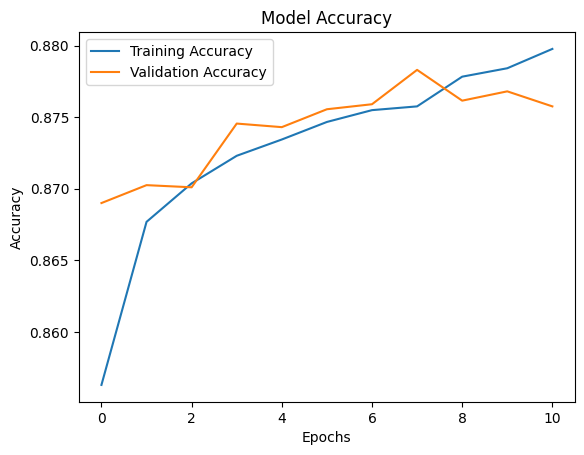

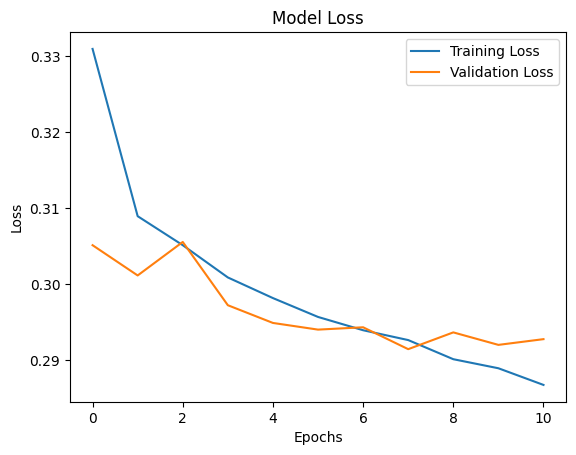

In [ ]:
import matplotlib.pyplot as plt

# Menampilkan grafik akurasi
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Menampilkan grafik loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


# Confusion Matrix

625/625 ━━━━━━━━━━━━━━━━━━━━ 38s 61ms/step


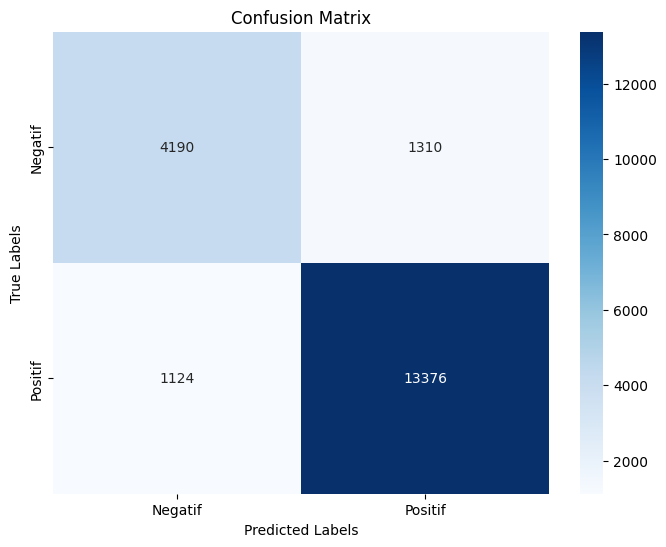

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Melakukan prediksi pada data uji
y_pred = model.predict(X_test)

# Mengambil kelas dengan probabilitas tertinggi
y_pred_classes = np.argmax(y_pred, axis=1)

# Mengambil kelas sebenarnya
y_true_classes = np.argmax(y_test, axis=1)

# Menghitung confusion matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)

# Menampilkan confusion matrix
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negatif', 'Positif'], yticklabels=['Negatif', 'Positif'])
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

# Word Cloud

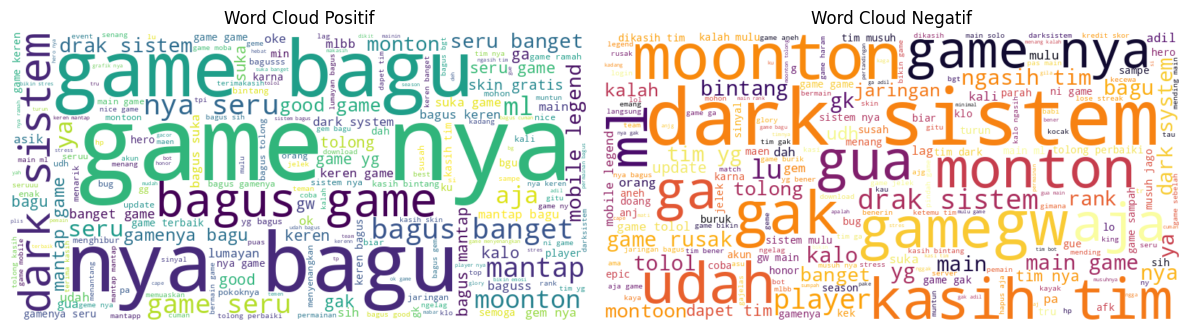

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Pisahkan data menjadi ulasan positif dan negatif berdasarkan skor
df_positive = df[df['score'] > 3]  # Ulasan dengan skor lebih dari 3 (positif)
df_negative = df[df['score'] < 3]  # Ulasan dengan skor kurang dari 3 (negatif)

# Gabungkan semua teks dalam kolom 'preprocessed_review' menjadi satu string untuk positif
positive_reviews = ' '.join([' '.join(review) for review in df_positive['preprocessed_review'].dropna()])

# Gabungkan semua teks dalam kolom 'preprocessed_review' menjadi satu string untuk negatif
negative_reviews = ' '.join([' '.join(review) for review in df_negative['preprocessed_review'].dropna()])

# Membuat word cloud untuk ulasan positif
wordcloud_positive = WordCloud(width=800, height=400, background_color='white',
                               max_words=200, colormap='viridis').generate(positive_reviews)

# Membuat word cloud untuk ulasan negatif
wordcloud_negative = WordCloud(width=800, height=400, background_color='white',
                               max_words=200, colormap='inferno').generate(negative_reviews)

# Menampilkan word cloud positif dan negatif dalam satu plot
plt.figure(figsize=(12, 6))

# Subplot untuk word cloud positif
plt.subplot(1, 2, 1)
plt.imshow(wordcloud_positive, interpolation='bilinear')
plt.axis('off')  # Menyembunyikan axis
plt.title('Word Cloud Positif')

# Subplot untuk word cloud negatif
plt.subplot(1, 2, 2)
plt.imshow(wordcloud_negative, interpolation='bilinear')
plt.axis('off')  # Menyembunyikan axis
plt.title('Word Cloud Negatif')

plt.tight_layout()
plt.show()


# Frekuensi Bigram

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd
import numpy as np

# Gabungkan semua teks dalam kolom 'preprocessed_review' menjadi satu list
reviews = df['preprocessed_review'].dropna().apply(lambda x: ' '.join(x))  # Menggabungkan token menjadi string

# Inisialisasi CountVectorizer untuk mencari bigram atau trigram
vectorizer = CountVectorizer(ngram_range=(2, 2), max_features=20)  # Untuk bigram (2 kata), ubah ke (3, 3) untuk trigram

# Fit dan transform teks untuk menghitung frekuensi n-gram
X = vectorizer.fit_transform(reviews)

# Ambil n-gram dan frekuensinya
n_grams = vectorizer.get_feature_names_out()
frequencies = np.asarray(X.sum(axis=0)).flatten()

# Membuat DataFrame untuk melihat n-gram yang sering muncul
ngram_df = pd.DataFrame(list(zip(n_grams, frequencies)), columns=['n-gram', 'Frequency'])

# Mengurutkan berdasarkan frekuensi
ngram_df = ngram_df.sort_values(by='Frequency', ascending=False)

# Menampilkan n-gram yang paling sering muncul
print(ngram_df.head(20))  # Menampilkan 20 n-gram teratas


             n-gram  Frequency
5          game nya       6955
1       dark sistem       4853
14        nya bagus       3389
4        game bagus       2963
3       drak sistem       1997
10        kasih tim       1759
0      bagus banget       1500
15         nya seru       1428
2       dark system       1274
7         game seru       1241
18           tim yg       1111
13       ngasih tim       1103
11        main game       1072
9     gamenya bagus        909
16      seru banget        898
6        game rusak        878
19  tolong perbaiki        847
8           game yg        837
17          tim nya        832
12   mobile legends        802


# Frekuensi Kata pada Teks yang Telah Diproses

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd
import numpy as np

# Gabungkan semua teks dalam kolom 'preprocessed_review' menjadi satu list
reviews = df['preprocessed_review'].dropna().apply(lambda x: ' '.join(x))  # Menggabungkan token menjadi string

# Inisialisasi CountVectorizer untuk mencari kata-kata yang sering muncul
vectorizer = CountVectorizer(max_features=20)  # Menampilkan 20 kata yang paling sering muncul

# Fit dan transform teks untuk menghitung frekuensi kata
X = vectorizer.fit_transform(reviews)

# Ambil kata-kata dan frekuensinya
words = vectorizer.get_feature_names_out()
frequencies = np.asarray(X.sum(axis=0)).flatten()

# Membuat DataFrame untuk melihat kata-kata yang sering muncul
word_df = pd.DataFrame(list(zip(words, frequencies)), columns=['Word', 'Frequency'])

# Mengurutkan berdasarkan frekuensi
word_df = word_df.sort_values(by='Frequency', ascending=False)

# Menampilkan kata yang paling sering muncul
print(word_df.head(20))  # Menampilkan 20 kata teratas


       Word  Frequency
6      game      36653
1     bagus      23262
14      nya      18809
17      tim      11593
9      main       9500
16   sistem       9158
15     seru       8468
8     kasih       6824
3      dark       6801
19       yg       6521
18   tolong       6247
13  moonton       6238
5       gak       5533
2    banget       4981
4        ga       4819
7        gw       4669
10   mantap       4653
0       aja       4573
12   monton       3783
11       ml       3688


# Word Cloud Bigram

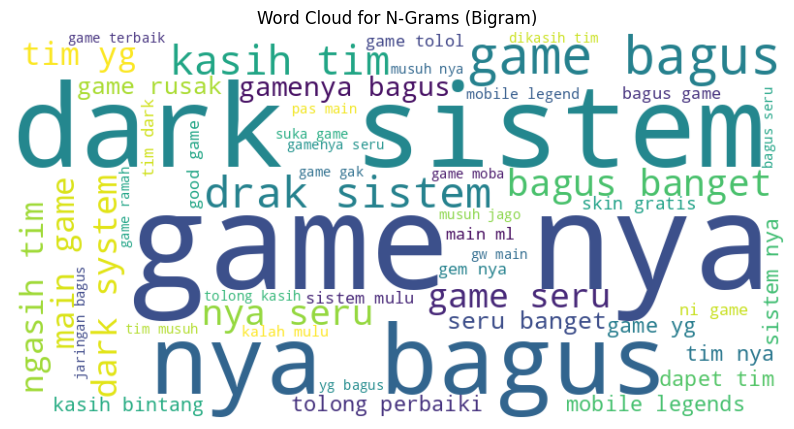

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Gabungkan semua teks dalam kolom 'preprocessed_review' menjadi satu list
reviews = df['preprocessed_review'].dropna().apply(lambda x: ' '.join(x))  # Menggabungkan token menjadi string

# Inisialisasi CountVectorizer untuk mencari bigram (2 kata) atau trigram (3 kata)
vectorizer = CountVectorizer(ngram_range=(2, 2), max_features=50)  # Ganti (2, 2) dengan (3, 3) untuk trigram

# Fit dan transform teks untuk menghitung frekuensi n-gram
X = vectorizer.fit_transform(reviews)

# Ambil n-gram dan frekuensinya
n_grams = vectorizer.get_feature_names_out()
frequencies = np.asarray(X.sum(axis=0)).flatten()

# Gabungkan n-gram dan frekuensinya dalam dictionary
ngram_dict = dict(zip(n_grams, frequencies))

# Membuat WordCloud
wordcloud = WordCloud(width=800, height=400, background_color='white',
                      max_words=50, colormap='viridis').generate_from_frequencies(ngram_dict)

# Menampilkan WordCloud
plt.figure(figsize=(10, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')  # Menyembunyikan axis
plt.title("Word Cloud for N-Grams (Bigram)")
plt.show()


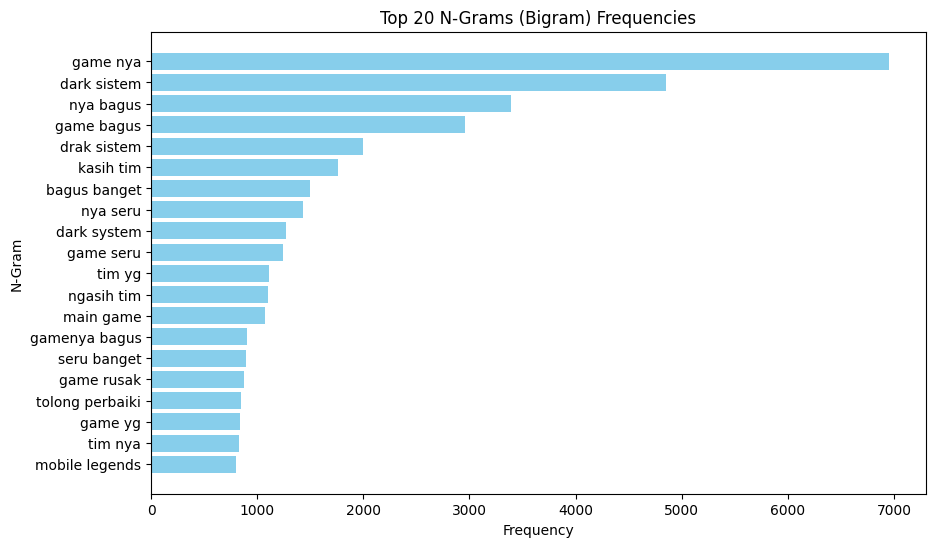

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Gabungkan semua teks dalam kolom 'preprocessed_review' menjadi satu list
reviews = df['preprocessed_review'].dropna().apply(lambda x: ' '.join(x))  # Menggabungkan token menjadi string

# Inisialisasi CountVectorizer untuk mencari bigram (2 kata) atau trigram (3 kata)
vectorizer = CountVectorizer(ngram_range=(2, 2), max_features=20)  # Ganti (2, 2) dengan (3, 3) untuk trigram

# Fit dan transform teks untuk menghitung frekuensi n-gram
X = vectorizer.fit_transform(reviews)

# Ambil n-gram dan frekuensinya
n_grams = vectorizer.get_feature_names_out()
frequencies = np.asarray(X.sum(axis=0)).flatten()

# Membuat DataFrame untuk melihat n-gram yang sering muncul
ngram_df = pd.DataFrame(list(zip(n_grams, frequencies)), columns=['N-Gram', 'Frequency'])

# Mengurutkan berdasarkan frekuensi
ngram_df = ngram_df.sort_values(by='Frequency', ascending=False)

# Membuat bar chart
plt.figure(figsize=(10, 6))
plt.barh(ngram_df['N-Gram'], ngram_df['Frequency'], color='skyblue')
plt.xlabel('Frequency')
plt.ylabel('N-Gram')
plt.title('Top 20 N-Grams (Bigram) Frequencies')
plt.gca().invert_yaxis()  # Membalik urutan agar yang paling sering muncul di atas
plt.show()


# Word Cloud Kata yang Sering Muncul

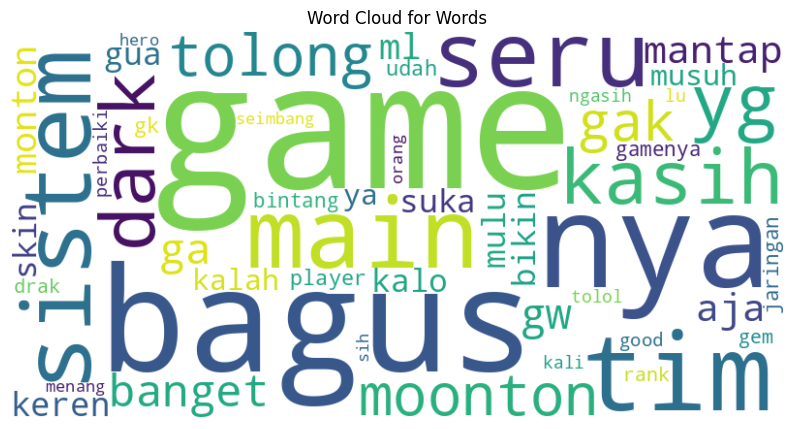

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Gabungkan semua teks dalam kolom 'preprocessed_review' menjadi satu list
reviews = df['preprocessed_review'].dropna().apply(lambda x: ' '.join(x))  # Menggabungkan token menjadi string

# Inisialisasi CountVectorizer untuk mencari kata-kata yang sering muncul
vectorizer = CountVectorizer(max_features=50)  # Menampilkan 50 kata yang paling sering muncul

# Fit dan transform teks untuk menghitung frekuensi kata
X = vectorizer.fit_transform(reviews)

# Ambil kata-kata dan frekuensinya
words = vectorizer.get_feature_names_out()
frequencies = np.asarray(X.sum(axis=0)).flatten()

# Gabungkan kata-kata dan frekuensinya dalam dictionary
word_dict = dict(zip(words, frequencies))

# Membuat WordCloud
wordcloud = WordCloud(width=800, height=400, background_color='white',
                      max_words=50, colormap='viridis').generate_from_frequencies(word_dict)

# Menampilkan WordCloud
plt.figure(figsize=(10, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')  # Menyembunyikan axis
plt.title("Word Cloud for Words")
plt.show()


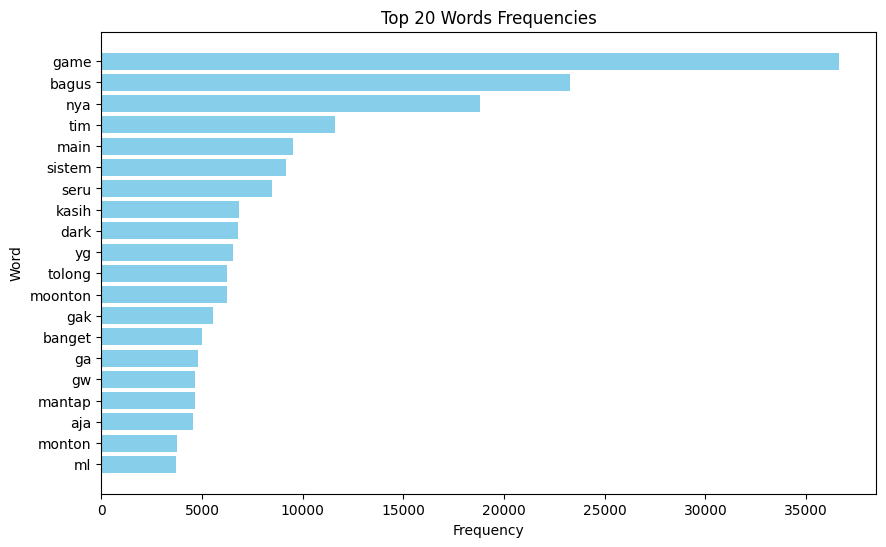

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Gabungkan semua teks dalam kolom 'preprocessed_review' menjadi satu list
reviews = df['preprocessed_review'].dropna().apply(lambda x: ' '.join(x))  # Menggabungkan token menjadi string

# Inisialisasi CountVectorizer untuk mencari kata-kata yang sering muncul
vectorizer = CountVectorizer(max_features=20)  # Menampilkan 20 kata yang paling sering muncul

# Fit dan transform teks untuk menghitung frekuensi kata
X = vectorizer.fit_transform(reviews)

# Ambil kata-kata dan frekuensinya
words = vectorizer.get_feature_names_out()
frequencies = np.asarray(X.sum(axis=0)).flatten()

# Membuat DataFrame untuk melihat kata-kata yang sering muncul
word_df = pd.DataFrame(list(zip(words, frequencies)), columns=['Word', 'Frequency'])

# Mengurutkan berdasarkan frekuensi
word_df = word_df.sort_values(by='Frequency', ascending=False)

# Membuat bar chart
plt.figure(figsize=(10, 6))
plt.barh(word_df['Word'], word_df['Frequency'], color='skyblue')
plt.xlabel('Frequency')
plt.ylabel('Word')
plt.title('Top 20 Words Frequencies')
plt.gca().invert_yaxis()  # Membalik urutan agar yang paling sering muncul di atas
plt.show()


# Distribusi Ulasan Positif dan Negatif

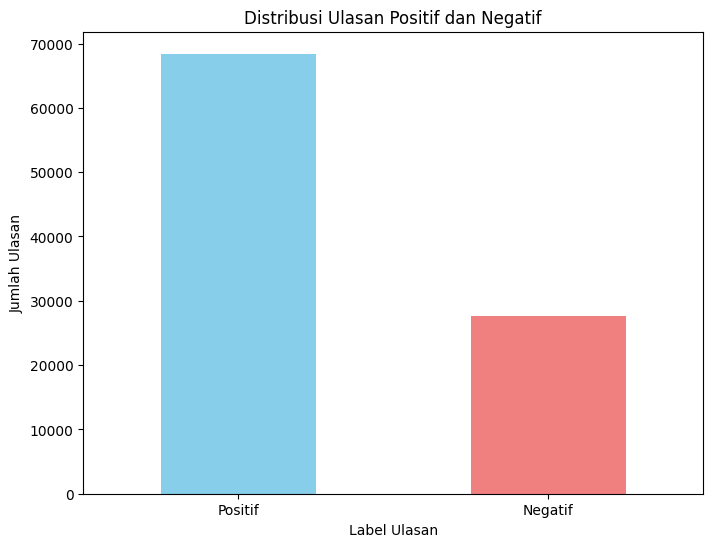

In [ ]:
import matplotlib.pyplot as plt

# Hitung jumlah ulasan positif dan negatif
label_counts = scrap_data['Label'].value_counts()

# Membuat Bar Chart
plt.figure(figsize=(8, 6))
label_counts.plot(kind='bar', color=['skyblue', 'lightcoral'])
plt.xlabel('Label Ulasan')
plt.ylabel('Jumlah Ulasan')
plt.title('Distribusi Ulasan Positif dan Negatif')
plt.xticks(rotation=0)  # Agar label sumbu x tidak miring
plt.show()
